In [54]:
from io import StringIO
import pandas as pd
import requests
import json, re, time
from pathlib import Path
from rapidfuzz import fuzz, process
from tqdm import tqdm
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def requestConstituents(url, table_id):
    response = requests.get(
        url,
        headers={"User-Agent": "AAIS student project"},
        timeout=30,
    )
    response.raise_for_status()

    tables = pd.read_html(
        StringIO(response.text),
        attrs={"id": table_id},
        flavor="lxml",
    )
    df = tables[0]
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = [
            "_".join(dict.fromkeys(str(level) for level in column if level))
            for column in df.columns
        ]
    df.columns = df.columns.str.lower().str.replace(" ", "_")
 
    
    return df

constituents_df = (
    requestConstituents(
        "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
        "constituents",
    )
)
history_df = (
    requestConstituents(
        "https://en.wikipedia.org/wiki/Historical_components_of_the_S&P_500",
          "changes",
          )
)
constituents_df["yahoo_symbol"] = constituents_df["symbol"].str.replace(".", "-", regex=False)

history_df['yahoo_added_ticker'] = history_df['added_ticker'].str.replace(".", "-", regex=False)
history_df['yahoo_removed_ticker'] = history_df['removed_ticker'].str.replace(".", "-", regex=False)


In [ ]:
def canonical_ticker(ticker, date, renames = {}):
    for _ in range(5): 
        rule = renames.get(ticker)
        if rule is None:
            break
        new, cutoff = rule
        if cutoff is not None and date >= pd.Timestamp(cutoff):
            break
        ticker = new
    return ticker


def prepare_events_df(history_df):
    df = history_df.copy()
    df["date"] = pd.to_datetime(df["effective_date"], format="%B %d, %Y", errors="coerce")

    added = df[["date", "yahoo_added_ticker"]].rename(columns={"yahoo_added_ticker": "ticker"}).assign(action="add")
    removed = df[["date", "yahoo_removed_ticker"]].rename(columns={"yahoo_removed_ticker": "ticker"}).assign(action="remove")

    events_df = pd.concat([added, removed], ignore_index=True)
    events_df["ticker"] = events_df["ticker"].astype("string").str.strip()
    events_df = events_df.dropna(subset=["date", "ticker"])
    events_df = events_df[events_df["ticker"] != ""]

    
    events_df["ticker"] = [canonical_ticker(t, d) for t, d in zip(events_df["ticker"], events_df["date"])]

   
    events_df["order"] = events_df["action"].map({"remove": 0, "add": 1})
    events_df = events_df.sort_values(["date", "order"], kind="stable")
    return events_df.drop(columns="order").reset_index(drop=True)


def members_on(intervals, date):
    d = pd.Timestamp(date)
    started = intervals["start"].isna() | (intervals["start"] <= d)
    not_ended = intervals["end"].isna() | (intervals["end"] > d)
    return sorted(intervals.loc[started & not_ended, "ticker"])


In [4]:
events_df = prepare_events_df(history_df)
intervals = []

for event in events_df.itertuples():
    if event.action == "add":
        intervals.append((event.ticker, event.date, None))
    else:
        for i in range(len(intervals)):
            if intervals[i][0] == event.ticker and intervals[i][2] is None:
                intervals[i] = (intervals[i][0], intervals[i][1], event.date)
                break
        else:
            intervals.append((event.ticker, None, event.date))

constituents_df["date_added"] = pd.to_datetime(constituents_df["date_added"], errors="coerce")

open_tickers = {t for t, _, end in intervals if end is None}
orphans = []  
for row in constituents_df.itertuples():
    if row.yahoo_symbol not in open_tickers:
        orphans.append(row.yahoo_symbol)
        intervals.append((row.yahoo_symbol, row.date_added, None))


In [5]:
iv = pd.DataFrame(intervals, columns=["ticker", "start", "end"])

current = set(constituents_df["yahoo_symbol"])
open_mask = iv["end"].isna()
phantoms = sorted(set(iv.loc[open_mask, "ticker"]) - current)


ph = iv[open_mask & iv["ticker"].isin(phantoms)]
orph = constituents_df.loc[constituents_df["yahoo_symbol"].isin(orphans), ["yahoo_symbol", "security", "date_added"]]

print(ph.merge(orph, left_on="start", right_on="date_added", how="left")[["ticker", "start", "yahoo_symbol", "security"]].to_string())


iv = iv[~(open_mask & iv["ticker"].isin(phantoms))].reset_index(drop=True)


    ticker      start yahoo_symbol              security
0      BUD 1976-07-01          NaN                   NaN
1      NCC 1994-09-30         SKYD  Skydance Corporation
2      CCR 1997-06-17          NaN                   NaN
3      FSR 1998-12-11          NaN                   NaN
4      ACT 1999-04-12          NaN                   NaN
5      WLP 1999-06-09          NaN                   NaN
6      LUK 2007-08-24          NaN                   NaN
7      TSO 2007-09-27          NaN                   NaN
8      JEC 2007-10-26            J      Jacobs Solutions
9      COG 2008-06-23          NaN                   NaN
10     HRS 2008-09-16          NaN                   NaN
11    PCLN 2009-11-03          NaN                   NaN
12    JOYG 2011-02-25          NaN                   NaN
13    DLPH 2012-12-21          NaN                   NaN
14    KORS 2013-11-13          NaN                   NaN
15  ALLE | 2013-12-02         ALLE              Allegion
16      FB 2013-12-23         M

In [6]:
early, far = pd.Timestamp("1900-01-01"), pd.Timestamp("2100-01-01")
x = iv.assign(s=iv["start"].fillna(early), e=iv["end"].fillna(far)).sort_values(["ticker", "s"])


dates = pd.date_range("2005-01-01", pd.Timestamp.today(), freq="MS")
counts = pd.Series([len(members_on(iv, d)) for d in dates], index=dates)


In [7]:


SEC_HEADERS = {"User-Agent": "Name Surname email@example.com"}

DATA_DIR = Path("data")
(DATA_DIR / "companyfacts").mkdir(parents=True, exist_ok=True)

START, END = "2010-01-31", "2026-09-30"  
PRICE_START = "2009-06-01"               


def to_long(wide, name):
    return (wide.rename_axis(index="date", columns="ticker")
                .reset_index()
                .melt(id_vars="date", var_name="ticker", value_name=name))


def get_companyfacts(cik):
    path = DATA_DIR / "companyfacts" / f"CIK{int(cik):010d}.json"
    if path.exists():
        return json.loads(path.read_text())
    url = f"https://data.sec.gov/api/xbrl/companyfacts/CIK{int(cik):010d}.json"
    r = requests.get(url, headers=SEC_HEADERS, timeout=30)
    time.sleep(0.15)  
    if r.status_code not in (200, 404):
        r.raise_for_status()
    data = r.json() if r.status_code == 200 else {}
    path.write_text(json.dumps(data))
    return data

In [8]:
months = pd.date_range(START, END, freq="ME")
panel = pd.DataFrame(
    [(d, t) for d in months for t in members_on(iv, d)],
    columns=["date", "ticker"],
)

### Insertion of the cik number for tickets using information from Wikipedia, and manual insertion


In [9]:
h = history_df.copy()
h["date"] = pd.to_datetime(h["effective_date"], format="%B %d, %Y", errors="coerce")
h = h.dropna(subset=["date"]).sort_values("date")  

names = {}
for col_t, col_n in [("yahoo_added_ticker", "added_security"), ("yahoo_removed_ticker", "removed_security")]:
    for t, n, d in zip(h[col_t], h[col_n], h["date"]):
        if pd.notna(t) and pd.notna(n):
            names[canonical_ticker(str(t).strip(), d)] = n
names.update(dict(zip(constituents_df["yahoo_symbol"], constituents_df["security"])))

tickers_df = pd.DataFrame({"ticker": sorted(panel["ticker"].unique())})
tickers_df["name"] = tickers_df["ticker"].map(names)

SUFFIXES = r"\b(INC|INCORPORATED|CORP|CORPORATION|CO|COMPANY|LTD|LIMITED|PLC|LLC|LP|THE|NV|SA|AG)\b"

def norm_name(s):
    if pd.isna(s):
        return ""
    s = str(s).upper().replace("&", " AND ")
    s = re.sub(r"[^A-Z0-9 ]", " ", s)
    s = re.sub(SUFFIXES, " ", s)
    return " ".join(s.split())

In [10]:
tickers_df["cik"] = tickers_df["ticker"].map(
    dict(zip(constituents_df["yahoo_symbol"], pd.to_numeric(constituents_df["cik"], errors="coerce")))
)
tickers_df["cik_source"] = np.where(tickers_df["cik"].notna(), "wiki", None)


r = requests.get("https://www.sec.gov/files/company_tickers.json", headers=SEC_HEADERS, timeout=30)
r.raise_for_status()
sec_t = pd.DataFrame(r.json().values()).rename(columns={"cik_str": "sec_cik", "title": "sec_name"})
sec_t["ticker"] = sec_t["ticker"].str.replace(".", "-", regex=False)

cand = tickers_df[tickers_df["cik"].isna()].merge(sec_t, on="ticker", how="inner")
cand["score"] = [fuzz.token_sort_ratio(norm_name(a), norm_name(b)) for a, b in zip(cand["name"], cand["sec_name"])]
good = cand[cand["score"] >= 80].set_index("ticker")["sec_cik"]
tickers_df.loc[tickers_df["ticker"].isin(good.index), "cik_source"] = "sec_tickers"
tickers_df["cik"] = tickers_df["cik"].fillna(tickers_df["ticker"].map(good))



In [11]:
path = DATA_DIR / "cik-lookup-data.txt"
if not path.exists():
    r = requests.get("https://www.sec.gov/Archives/edgar/cik-lookup-data.txt", headers=SEC_HEADERS, timeout=300)
    r.raise_for_status()
    path.write_bytes(r.content)

rows = []
with open(path, encoding="latin-1") as f:
    for line in f:
        parts = line.rstrip("\n").rsplit(":", 2)   
        if len(parts) == 3 and parts[1].isdigit():
            rows.append((parts[0], int(parts[1])))
lookup = pd.DataFrame(rows, columns=["sec_name", "cik"])
lookup["norm"] = lookup["sec_name"].map(norm_name)
ciks_by_norm = lookup.groupby("norm")["cik"].apply(lambda s: sorted(set(s)))
choices = ciks_by_norm.index.tolist()


def pick_cik(ciks):
    best, best_n = None, -1
    for c in ciks[:5]:
        n = len(get_companyfacts(c).get("facts", {}).get("us-gaap", {}))
        if n > best_n:
            best, best_n = c, n
    return best if best_n > 0 else None


review = []
for i in tickers_df.index[tickers_df["cik"].isna()]:
    n = norm_name(tickers_df.at[i, "name"])
    if not n:
        continue
    match = process.extractOne(n, choices, scorer=fuzz.token_sort_ratio, score_cutoff=85)
    if match is None:
        review.append((tickers_df.at[i, "ticker"], tickers_df.at[i, "name"], None, None))
        continue
    matched_norm, score, _ = match
    cik = pick_cik(ciks_by_norm[matched_norm])
    review.append((tickers_df.at[i, "ticker"], tickers_df.at[i, "name"], matched_norm, score))
    if score >= 95 and cik is not None:
        tickers_df.at[i, "cik"] = cik
        tickers_df.at[i, "cik_source"] = "name_match"

review = pd.DataFrame(review, columns=["ticker", "name", "best_match", "score"])
print(review.sort_values("score").to_string())

    ticker                             name                        best_match       score
60     DFS               Discover Financial                 ANDOVER FINANCIAL   85.714286
195    TAP                     Molson Coors                  MOLSON COORS USA   85.714286
201    TSS                             TSYS                               SYS   85.714286
37    CELG                          Celgene                         GENE CELL   87.500000
170    RRD                     RR Donnelley                     DONNELLEY R H   88.000000
151     OI                   Owens-Illinois                 OWENS ILLINOIS DE   90.322581
216    WIN        Windstream Communications    WINDSTREAM IOWA COMMUNICATIONS   90.909091
121   LLTC                Linear Technology              LINEAR TECHNOLOGY CA   91.891892
95     HAR             Harman International             HAIRMAX INTERNATIONAL   92.682927
83     FII              Federated Investors            FEDERATED INVESTORS DE   92.682927
144    NFX

In [12]:
CIK_MANUAL = {
    "ZION": 109380,     # Zions Bancorporation
    "TAP": 24545,       # Molson Coors Beverage Co
    "IPG": 51644,       # Interpublic Group of Companies, Inc.
    "DFS": 1393612,     # Discover Financial Services
    "VFC": 103379,      # V.F. Corporation
    "SEE": 1867140,     # Sealed Air Corporation
    "UAA": 1336917,     # Under Armour, Inc. (Class A)
    "UNM": 5513,        # Unum Group
    "ETFC": 1015780,    # E*TRADE Financial Corp.
    "CELG": 816284,     # Celgene Corp.
    "TSS": 893438,      # Total System Services
    "PVH": 78239,       # PVH Corp.
    "AET": 1122304,     # Aetna, Inc.
    "CA": 66603,        # CA Technologies
    "MON": 1110783,     # Monsanto Co.
    "NFX": 1058299,     # Newfield Exploration Co.
    "UA": 1336917,      # Under Armour, Inc. (Class C)
    "BCR": 8670,        # C. R. Bard, Inc.
    "MJN": 1452575,     # Mead Johnson Nutrition Co.
    "LW": 1679273,      # Lamb Weston Holdings, Inc.
    "HAR": 45791,     # Harman International Industries
    "LLTC": 791907,     # Linear Technology Corp (Przejęte przez Analog Devices)
    "OI": 812074,       # O-I Glass, Inc. (Dawniej Owens-Illinois)
    "HOT": 316206,      # Starwood Hotels & Resorts Worldwide (Przejęte przez Marriott)
    "MKTX": 1278021,    # MarketAxess Holdings Inc.
    "PAYC": 1590955,    # Paycom Software, Inc.
    "FDO": 34408,       # Family Dollar Stores (Przejęte przez Dollar Tree)
    "CVC": 1053112,     # Cablevision Systems Corp (Przejęte przez Altice USA)
    "LO": 1424847,      # Lorillard, Inc. (Przejęte przez Reynolds American)
    "WIN": 1282266,     # Windstream Holdings (Zrestrukturyzowane / Prywatne)
    "BEAM": 789073,     # Beam Inc. (Przejęte przez Suntory)
    "FRC": 1492092,     # First Republic Bank (Upadłość / Przejęte przez JPMorgan Chase)
    "JCP": 1166126,     # J. C. Penney Co Inc (Upadłość / Prywatne)
    "JDSU": 912093,     # JDS Uniphase Corp (Zmienione na Viavi Solutions / Lumentum)
    "HNZ": 46640,       # H. J. Heinz Co (Połączone w The Kraft Heinz Company)
    "PCS": 1283699,     # MetroPCS Communications (Połączone z T-Mobile US)
    "FII": 1056288,     # Federated Investors Inc (Obecnie Federated Hermes - FHI)
    "RRD": 29669,       # R.R. Donnelley & Sons Co (Wykupione / Prywatne)
    "LXK": 1001288,     # Lexmark International Inc (Przejęte / Prywatne)
    "MXIM": 743316,     # Maxim Integrated Products (Przejęte przez Analog Devices)
    "SEDG": 1419612,     # SolarEdge Technologies, Inc.
    "JCP |": 1166126,     # J. C. Penney Co Inc (Upadłość / Prywatne)
    "AKS": 918160,      # AK Steel Holding Corp (Przejęte przez Cleveland-Cliffs)
    "DWDP": 1666700,    # DowDuPont Inc. (Rozdzielone na Dow, DuPont i Corteva)
    "MMI": 1058083,     # IMS Health Holdings (Połączone w IQVIA)
    "WCG": 1279363,     # WellCare Health Plans (Przejęte przez Centene)
    "SBNY": 1288784,    # Signature Bank (Upadłość / Zamknięte)
    "MIL": 66479,       # Millipore Corp (Przejęte przez Merck KGaA)
    "CMCSK": 1166691,   # Comcast Corp (Klasa K - akcje bez prawa głosu, skonsolidowane)
    "AMTM": 2011286,    # Amentum Holdings, Inc.
    "RX": 1058083       # IMS Health Inc. (Historyczny ticker przed rebrandingiem)
}
for t, c in CIK_MANUAL.items():
    tickers_df.loc[tickers_df["ticker"] == t, ["cik", "cik_source"]] = [c, "manual"]

panel = panel.drop(columns=["cik"], errors="ignore").merge(tickers_df[["ticker", "cik"]], on="ticker", how="left")

In [13]:
panel["date"] = pd.to_datetime(panel["date"])
print(panel["cik"].isna().sum())
print(panel.loc[panel["cik"].isna(), "ticker"].value_counts().head(20))
r = requests.get("https://www.sec.gov/files/company_tickers.json", headers=SEC_HEADERS).json()
cik2tic = {}
for v in r.values():
    cik2tic.setdefault(v["cik_str"], v["ticker"])   

panel["yf"] = panel["cik"].map(cik2tic).fillna(panel["ticker"]).str.replace(".", "-", regex=False)

0
Series([], Name: count, dtype: int64)


In [14]:
panel['cik'] = panel['cik'].astype(int)

In [15]:
EPS_TAGS = ["EarningsPerShareDiluted", "EarningsPerShareBasic", "EarningsPerShareBasicAndDiluted"]

from functools import lru_cache

@lru_cache(maxsize=None)
def companyfacts(cik):
    r = requests.get(f"https://data.sec.gov/api/xbrl/companyfacts/CIK{int(cik):010d}.json",
                     headers=SEC_HEADERS)
    time.sleep(0.12)
    return r.json() if r.status_code == 200 else None


def eps_ttm(cik):
    cf = companyfacts(cik)
    gaap = (cf or {}).get("facts", {}).get("us-gaap", {})
    tag = next((t for t in EPS_TAGS if t in gaap), None)
    if tag is None:
        return None
    df = pd.DataFrame(gaap[tag]["units"].get("USD/shares", []))
    if df.empty or "start" not in df:
        return None
    df = df[df["form"].isin(["10-K", "10-Q", "10-K/A", "10-Q/A"])].copy()
    for c in ["start", "end", "filed"]:
        df[c] = pd.to_datetime(df[c])
    df["days"] = (df["end"] - df["start"]).dt.days
    
    df = df.sort_values("filed").drop_duplicates(["start", "end"], keep="first")
    cols = ["start", "end", "val", "filed"]
    q   = df[df["days"].between(80, 100)][cols]
    fy  = df[df["days"].between(350, 380)][cols]
    ytd = df[df["days"].between(260, 285)][cols]
    m = fy.merge(ytd, on="start", suffixes=("", "_9m"))
    q4 = pd.DataFrame({"start": m["end_9m"] + pd.Timedelta(days=1), "end": m["end"],
                       "val": m["val"] - m["val_9m"], "filed": m["filed"]})
    q = pd.concat([q, q4]).sort_values(["end", "filed"]).drop_duplicates("end")
    q["eps_ttm"] = q["val"].rolling(4).sum()
    gap = (q["end"] - q["end"].shift(3)).dt.days
    q.loc[~gap.between(250, 300), "eps_ttm"] = np.nan   
    out = q.dropna(subset=["eps_ttm"]).rename(columns={"filed": "date_eps", "end": "period_end"})
    return out[["period_end", "date_eps", "eps_ttm"]].assign(cik=cik)

eps = pd.concat([e for c in tqdm(panel["cik"].unique()) if (e := eps_ttm(c)) is not None])

panel["date"] = pd.to_datetime(panel["date"])
panel = pd.merge_asof(panel.sort_values("date"), eps.sort_values("date_eps"),
                      left_on="date", right_on="date_eps", by="cik", direction="backward")


panel.loc[(panel["date"] - panel["period_end"]).dt.days > 460, "eps_ttm"] = np.nan

100%|██████████| 798/798 [06:54<00:00,  1.93it/s]


In [39]:
eps

,period_end,date_eps,eps_ttm,cik
9,2009-04-30,2010-06-07,0.98,1090872
12,2009-07-31,2009-10-05,0.47,1090872
1,2009-10-31,2009-12-21,-0.10,1090872
19,2010-01-31,2010-03-10,-0.06,1090872
23,2010-04-30,2010-06-07,0.54,1090872
...,...,...,...,...
61,2025-08-03,2025-09-10,0.41,1474432
64,2025-11-02,2025-12-10,0.38,1474432
5,2026-02-01,2026-03-25,0.55,1474432
66,2026-05-03,2026-06-05,0.66,1474432


In [16]:
new_panel = panel.copy()

In [17]:
new_panel

,date,ticker,cik,yf,period_end,date_eps,eps_ttm
0,2010-01-31,A,1090872,A,2009-10-31,2009-12-21,-0.10
1,2010-01-31,PBCT,1378946,PBCT,2009-09-30,2009-11-09,0.32
2,2010-01-31,PAYX,723531,PAYX,2009-11-30,2009-12-16,1.37
3,2010-01-31,OXY,797468,OXY,2009-09-30,2009-11-02,3.00
4,2010-01-31,ORLY,898173,ORLY,NaT,NaT,NaN
...,...,...,...,...,...,...,...
100836,2026-09-30,EMR,32604,EMR,2025-12-31,2026-02-03,4.09
100837,2026-09-30,EME,105634,EME,2026-06-30,2026-07-30,32.13
100838,2026-09-30,ELV,1156039,ELV,2026-06-30,2026-07-15,22.57
100839,2026-09-30,EXC,1109357,EXC,2021-12-31,2022-02-25,NaN


In [18]:
dat = yf.download(new_panel['yf'].unique().tolist(), start="2009-01-01", end="2026-10-01", auto_adjust=False, actions=True, progress=False)
close = dat['Close'] 

failed = close.columns[close.isna().all()].tolist()



new_panel = new_panel[~new_panel['yf'].isin(failed)].copy()


$NSM: possibly delisted; no timezone found
$CTXS: possibly delisted; no timezone found
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: RSH"}}}
$MON: possibly delisted; no timezone found
$RSH: possibly delisted; no timezone found
$TSS: possibly delisted; no timezone found
$VIAB: possibly delisted; no timezone found
$PDCO: possibly delisted; no timezone found
$JWN: possibly delisted; no timezone found
$X: possibly delisted; no timezone found
$LVLT: possibly delisted; no timezone found
$HCBK: possibly delisted; no timezone found
$SIAL: possibly delisted; no timezone found
$PTV: possibly delisted; no timezone found
$AET: possibly delisted; no timezone found
$FTR: possibly delisted; no timezone found
$CCE: possibly delisted; no timezone found
$COL: possibly delisted; no timezone found
$CEPH: possibly delisted; no timezone found
$NBL: possibly delisted; no timezone found
$BRCM: possibly delisted; no timezone found
$FRX: po

In [19]:
dat_long = (
    dat.stack(level='Ticker', future_stack=True)  
       .reset_index()                              
)
dat_long.columns.name = None

In [20]:
dat_long['Date'] = pd.to_datetime(dat_long['Date']).astype('M8[ns]')  
new_panel['date'] = pd.to_datetime(new_panel['date']).astype('M8[ns]')  



new_panel = pd.merge_asof(new_panel, dat_long, left_on='date', right_on='Date',
    left_by='yf', right_by='Ticker', direction='backward', tolerance=pd.Timedelta('3D'))

In [21]:
new_panel = new_panel.dropna(subset=['eps_ttm'])
new_panel = new_panel.dropna(subset=['period_end'])

In [ ]:
new_panel = new_panel.reset_index()

In [36]:
new_panel['EarningsYield'] = new_panel['eps_ttm'] / new_panel['Close']
new_panel = new_panel[(new_panel['EarningsYield'] < 0.6) & (new_panel['EarningsYield'] > -0.6)]

In [48]:

new_panel["ey_rank_pct"] = (
    new_panel.groupby("date")["EarningsYield"]
    .rank(method="average", ascending=True, pct=True)
)

new_panel["is_long_decile"] = new_panel["ey_rank_pct"] >= 0.90
new_panel["is_short_decile"] = new_panel["ey_rank_pct"] <= 0.10

top_long_decile = (
    new_panel.loc[new_panel["is_long_decile"], ["date", "ticker", "EarningsYield", "Close", "eps_ttm", "cik", "yf"]]
    .sort_values(["date", "EarningsYield"], ascending=[True, False])
    .reset_index(drop=True)
)

top_short_decile = (
    new_panel.loc[new_panel["is_short_decile"], ["date", "ticker", "EarningsYield", "Close", "eps_ttm", "cik", "yf"]]
    .sort_values(["date", "EarningsYield"], ascending=[True, True])
    .reset_index(drop=True)
)


print(top_long_decile)
print(top_short_decile)
print(f"Long rows: {len(top_long_decile)} | Short rows: {len(top_short_decile)}")

           date ticker  EarningsYield       Close  eps_ttm      cik    yf
0    2010-01-31    CSX       0.581661    4.762222     2.77   277948   CSX
1    2010-01-31     CF       0.534676   18.572001     9.93  1324404    CF
2    2010-01-31    GME       0.475468    4.942500     2.35  1326380   GME
3    2010-01-31     MA       0.429772   24.990000    10.74  1141391    MA
4    2010-01-31    NEE       0.338802   12.190000     4.13   753308   NEE
...         ...    ...            ...         ...      ...      ...   ...
7876 2026-09-30   LDOS       0.087909  121.830002    10.71  1336920  LDOS
7877 2026-09-30    MTB       0.086994  217.600006    18.93    36270   MTB
7878 2026-09-30     CB       0.086979  325.250000    28.29   896159    CB
7879 2026-09-30    ZTS       0.086925   69.830002     6.07  1555280   ZTS
7880 2026-09-30    USB       0.086911   57.759998     5.02    36104   USB

[7881 rows x 7 columns]
           date ticker  EarningsYield       Close  eps_ttm      cik    yf
0    2010-01-

In [49]:
from pandas.tseries.offsets import MonthEnd

next_px = new_panel[['date', 'ticker', 'Close']].copy()
next_px['date'] = next_px['date'] - MonthEnd(1)  
next_px = next_px.rename(columns={'Close': 'Close_next'})

def add_next_price(decile_df):
    out = decile_df.merge(next_px, on=['date', 'ticker'], how='left')
    out['ret_next'] = out['Close_next'] / out['Close'] - 1
    return out

top_long_decile  = add_next_price(top_long_decile)
top_short_decile = add_next_price(top_short_decile)

print(top_long_decile[['date', 'ticker', 'Close', 'Close_next', 'ret_next']].head())

        date ticker      Close  Close_next  ret_next
0 2010-01-31    CSX   4.762222    5.273333  0.107326
1 2010-01-31     CF  18.572001   21.247999  0.144088
2 2010-01-31    GME   4.942500    4.300000 -0.129995
3 2010-01-31     MA  24.990000   22.437000 -0.102161
4 2010-01-31    NEE  12.190000   11.592500 -0.049016


In [52]:
long_ret  = top_long_decile.groupby('date')['ret_next'].mean()
short_ret = top_short_decile.groupby('date')['ret_next'].mean()
ls_ret = (long_ret - short_ret).dropna()

In [57]:
wealth

,Long (top EY),Short (bottom EY),Long – Short
date,,,
2010-01-31,1.000000,1.000000,1.000000
2010-02-28,1.023466,1.023927,0.999538
2010-03-31,1.091939,1.125575,0.967184
2010-04-30,1.110995,1.149473,0.963528
2010-05-31,1.025841,1.018068,0.999825
...,...,...,...
2026-05-31,10.719274,6.515031,1.448203
2026-06-30,11.046113,6.534240,1.488090
2026-07-31,11.836116,6.378253,1.630040


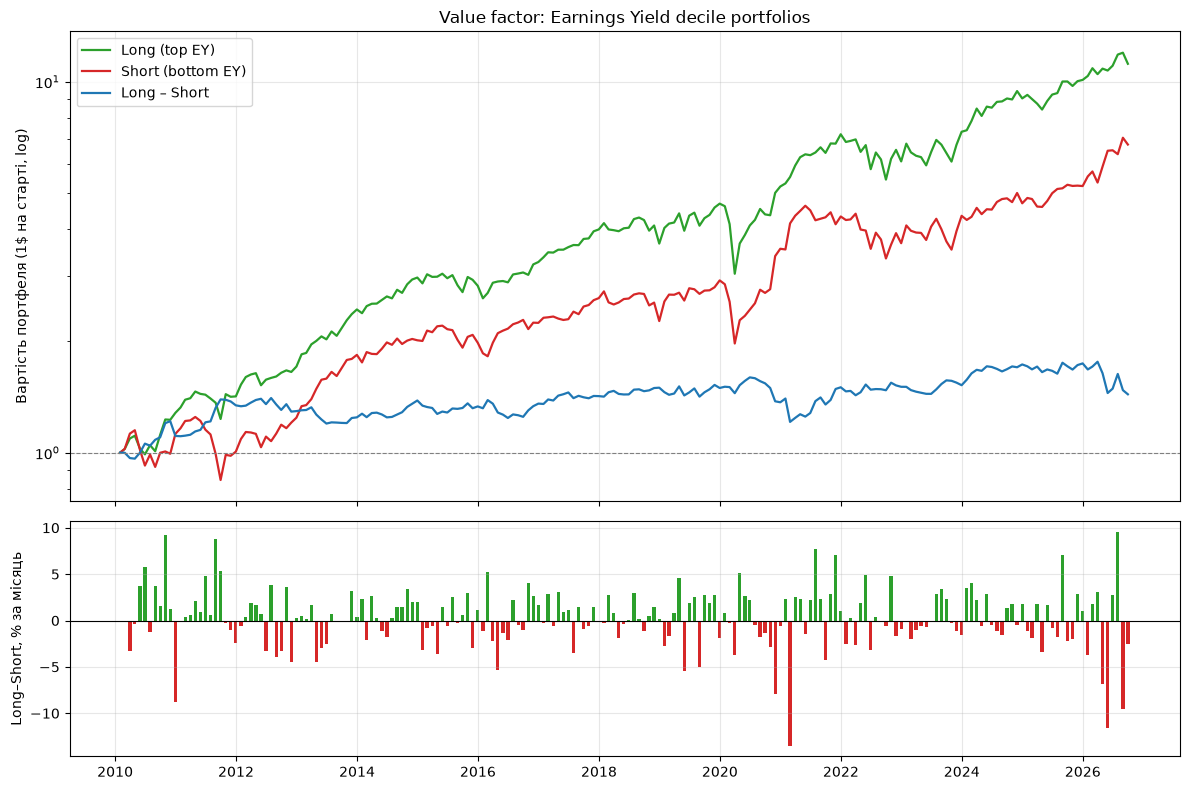

In [ ]:
rets = pd.DataFrame({
    'Long (top EY)':     long_ret,
    'Short (bottom EY)': short_ret,
}).dropna()
rets['Long – Short'] = rets['Long (top EY)'] - rets['Short (bottom EY)']



rets.index = rets.index + MonthEnd(1)

wealth = (1 + rets).cumprod()
start = wealth.index[0] - MonthEnd(1)
wealth.loc[start] = 1.0         
wealth = wealth.sort_index()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})


for col, c in zip(wealth.columns, ['tab:green', 'tab:red', 'tab:blue']):
    ax1.plot(wealth.index, wealth[col], label=col, color=c, lw=1.6)
ax1.axhline(1, color='grey', lw=0.8, ls='--')
ax1.set_yscale('log')
ax1.set_ylabel('Portolio value, $')
ax1.set_title('Value factor: Earnings Yield decile portfolios')
ax1.legend()
ax1.grid(alpha=0.3)



ls = rets['Long – Short']
ax2.bar(ls.index, ls * 100, width=20,
        color=['tab:green' if x >= 0 else 'tab:red' for x in ls])
ax2.axhline(0, color='black', lw=0.8)
ax2.set_ylabel('Long–Short, per months')
ax2.grid(alpha=0.3)
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.show()